# 11 · Segunda evaluación en test: el detector final

**Pregunta de este notebook.** ¿Se sostiene la hipótesis H con el **detector final** (`src/detector_final.py`), armado solo con desarrollo en `07` a `09`? Se aplica a los 20 registros de test (10 personas) con sus parámetros congelados (`docs/parametros_final.json`) y se miden las mismas tres predicciones de `05`, con el mismo criterio:

| Predicción | Qué se mide | Se cumple si |
|---|---|---|
| **P1**, dentro de la noche | AUC dentro de la noche de P_RR, en cada registro con al menos 20 minutos de cada tipo | la media es > 0,5 y su IC 95 % (bootstrap por persona) no incluye 0,5 |
| **P2**, entre noches | Spearman entre el nivel nocturno de la EDR y el % de minutos con apnea de cada registro | ρ > 0 y su IC 95 % no incluye 0 |
| **P3**, detección | AUC de C con todos los minutos; sensibilidad, especificidad y exactitud con el umbral fijo | AUC > 0,5 y su IC 95 % no incluye 0,5 |

**H se sostiene si se cumplen las tres.** El plan completo, escrito y subido antes de correr este notebook, está en `docs/plan_test_final.md`.

**Reglas.**
- No se ajusta nada con test. Los parámetros se leen del archivo congelado, y antes de abrir test se verifica que desarrollo los reproduce.
- Se corre **una sola vez**. La versión sin ejecutar quedó registrada en el repositorio antes de la ejecución, probada en **modo ensayo** con personas de desarrollo.
- **No es una evaluación ciega.** Test ya se usó en `05` con la versión anterior, y `06` analizó sus fallas (`objetivos_hipotesis.md`, limitación 10).
- **P1 no aporta evidencia nueva.** Depende solo del RR, que es el mismo en las dos versiones. Se espera que repita el 0,869 de `05`, y sirve como control del cálculo.

In [1]:
import hashlib
import json
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.config import MIN_MINUTES_PER_CLASS, SPLIT_CSV
from src.detector_final import SHA256_PARAMS, cargar_params, sha256, tabla_final, verificar_qrs
from src.estadistica import holm, p_bootstrap
from src.evaluation.cv import GRILLA_W, auc, cv_c, metricas
from src.features.detector import c_score, evaluable, fit_c, load_params, minute_table, youden_threshold
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, save, setup

setup()
P = cargar_params()                       # falla si docs/parametros_final.json no es el archivo congelado
verificar_qrs(P)                          # falla si el detector de QRS no tiene las seis etapas congeladas
RUTA_EVAL = ROOT / "docs" / "parametros_test.json"
assert hashlib.sha256(RUTA_EVAL.read_bytes()).hexdigest() == "d2aa704837aa6543b3403fb5c11cade858c310da5d2cf7f25b6990ac503271c4"
P_EVAL = load_params(RUTA_EVAL)           # la versión evaluada en 05, solo para la pregunta secundaria 1
RES_05 = json.loads((ROOT / "docs" / "resultados_test.json").read_text())

split = pd.read_csv(SPLIT_CSV)
SUJETO, CATEG = split.set_index("record").subject, split.set_index("record").category
DEV = split[split.set == "dev"].record.tolist()
# Modo ensayo: prueba el código con 10 personas de desarrollo en lugar de test, sin abrir test.
ENSAYO = os.environ.get("NB11_ENSAYO") == "1"
if ENSAYO:
    # Personas de desarrollo con la misma composición que test: tantas con noches A, B y C como test (solo se usan
    # las categorías de la partición). Se recorren en orden de número, empezando por la categoría con menos personas.
    cats = split.groupby("subject").category.agg(set)
    meta = {c: sum(c in cats[u] for u in split[split.set == "test"].subject.unique()) for c in "ABC"}
    personas, cuenta = [], dict.fromkeys("ABC", 0)
    for c in sorted("ABC", key=meta.get):
        for u in sorted(split[split.set == "dev"].subject.unique()):
            if cuenta[c] < meta[c] and c in cats[u] and u not in personas and all(cuenta[k] + (k in cats[u]) <= meta[k] for k in "ABC"):
                personas.append(u)
                cuenta.update({k: cuenta[k] + 1 for k in cats[u]})
    assert cuenta == meta, (cuenta, meta)
    TEST = split[split.subject.isin(personas)].record.tolist()
    print("personas del ensayo:", sorted(personas), "· personas con noches de cada categoría:", cuenta)
else:
    TEST = split[split.set == "test"].record.tolist()
guardar = (lambda fig, nombre: None) if ENSAYO else save
print(("MODO ENSAYO (desarrollo): " if ENSAYO else "TEST: ") + f"{len(TEST)} registros de {SUJETO[TEST].nunique()} personas")
print("parámetros congelados, SHA-256", sha256()[:16], "…")
print(json.dumps({k: P[k] for k in ("mu1", "s1", "mu2", "s2", "w", "umbral")}, indent=1))

TEST: 20 registros de 10 personas
parámetros congelados, SHA-256 73344a364ee3bd27 …
{
 "mu1": -1.4915729639776574,
 "s1": 0.5902302539907761,
 "mu2": -1.9919863678366045,
 "s2": 0.5992052156417715,
 "w": 1.0,
 "umbral": 0.48134981497878243
}


## 1. Controles en desarrollo, antes de abrir test

Se aplica el detector final a los 47 registros de desarrollo. El notebook se detiene acá, sin calcular nada en test, si desarrollo no reproduce lo que quedó fijado:
1. los parámetros de `parametros_final.json` (μ₁, σ₁, μ₂, σ₂, w y el umbral), ajustados como en `08` §7;
2. la exactitud de la validación cruzada por personas de `08` §7 (0,830);
3. los parámetros de la versión evaluada (`parametros_test.json`) con los valores por defecto de `src/config.py`, ajustados como en `04` §14. Hacen falta para la pregunta secundaria 1.

In [2]:
def tabla(rec):
    tab, _ = tabla_final(rec, params=P)
    return tab.assign(subject=SUJETO[rec], category=CATEG[rec])


def tabla_evaluada(rec):
    tab = minute_table(rec)                      # valores por defecto de src/config.py: la versión evaluada en 05
    tab["C"] = c_score(tab, P_EVAL)
    tab["decision"] = (tab.C > P_EVAL["umbral"]).astype(int)
    tab["evaluado"] = evaluable(tab)
    return tab.assign(subject=SUJETO[rec], category=CATEG[rec])


with ProcessPoolExecutor(4) as ex:
    D = pd.concat(list(ex.map(tabla, DEV)), ignore_index=True)
    D_EV = pd.concat(list(ex.map(tabla_evaluada, DEV)), ignore_index=True)

# 1. Parámetros del detector final (como en 08 §7: minutos evaluados con P_RR y nivel EDR finitos)
MC = P["etapas"]["max_rr_corregidos_por_minuto"]
e_fit = D[D.evaluado & np.isfinite(D.P_RR) & np.isfinite(D.EDR_noche)].reset_index(drop=True)
w_dev = float(GRILLA_W[int(np.argmax([auc(c_score(e_fit, fit_c(e_fit, w_, max_corrected=MC)), e_fit.label) for w_ in GRILLA_W]))])
p_dev = fit_c(e_fit, w_dev, max_corrected=MC)
u_dev = youden_threshold(c_score(e_fit, p_dev).to_numpy(), e_fit.label.to_numpy())
control_1 = {k: (p_dev[k], P[k]) for k in ("mu1", "s1", "mu2", "s2", "w")} | {"umbral": (u_dev, P["umbral"])}
# 2. Validación cruzada por personas del detector final (08 §7)
r_dev = cv_c(e_fit)
exactitud_cv = float((r_dev.pred == r_dev.label).mean())
# 3. Parámetros de la versión evaluada (como en 04 §14: minutos evaluados sin ningún valor faltante)
e_ev = D_EV[evaluable(D_EV)].drop(columns=["C", "decision", "evaluado"]).dropna().reset_index(drop=True)
p_ev = fit_c(e_ev, 1.0)
u_ev = youden_threshold(c_score(e_ev, p_ev).to_numpy(), e_ev.label.to_numpy())
control_3 = {k: (p_ev[k], P_EVAL[k]) for k in ("mu1", "s1", "mu2", "s2")} | {"umbral": (u_ev, P_EVAL["umbral"])}

controles = pd.DataFrame([{"control": f"1 · detector final, {k}", "desarrollo": a, "archivo": b} for k, (a, b) in control_1.items()]
                         + [{"control": "2 · exactitud con validación cruzada", "desarrollo": exactitud_cv, "archivo": 0.830}]
                         + [{"control": f"3 · versión evaluada, {k}", "desarrollo": a, "archivo": b} for k, (a, b) in control_3.items()])
controles["coincide"] = [abs(a - b) < 1e-9 if not c.startswith("2") else round(a, 3) == b
                         for c, a, b in zip(controles.control, controles.desarrollo, controles.archivo)]
assert controles.coincide.all(), "desarrollo no reproduce lo que quedó fijado: no se abre test"
print("los tres controles se cumplen: se abre test")
controles.set_index("control")

los tres controles se cumplen: se abre test


,desarrollo,archivo,coincide
control,,,
"1 · detector final, mu1",-1.491573,-1.491573,True
"1 · detector final, s1",0.590230,0.590230,True
"1 · detector final, mu2",-1.991986,-1.991986,True
"1 · detector final, s2",0.599205,0.599205,True
"1 · detector final, w",1.000000,1.000000,True
"1 · detector final, umbral",0.481350,0.481350,True
2 · exactitud con validación cruzada,0.829967,0.830000,True
"3 · versión evaluada, mu1",-1.491573,-1.491573,True
"3 · versión evaluada, s1",0.590230,0.590230,True


## 2. La tabla por minuto en test

Para cada registro de test se corre el detector final sin ajustar nada (`tabla_final`): detector de QRS, refinamiento del pico R, limpieza del RR, EDR, Welch y nivel nocturno de la EDR, y después C y la decisión con los parámetros fijos. Los minutos evaluados son los mismos que en `05`: con etiqueta, con 20 % o menos de RR corregidos y sin valores faltantes. Los umbrales de F y del RR solo, que se usan solo en la pregunta secundaria 2, se fijan con desarrollo por Youden, igual que el de C.

In [3]:
with ProcessPoolExecutor(4) as ex:
    T = pd.concat(list(ex.map(tabla, TEST)), ignore_index=True)
    T_EV = pd.concat(list(ex.map(tabla_evaluada, TEST)), ignore_index=True)
COLS = ["P_RR", "P_EDR", "F", "C"]
et = T[T.evaluado].dropna(subset=COLS).reset_index(drop=True)
ed = D[D.evaluado].dropna(subset=COLS).reset_index(drop=True)
et_ev = T_EV[T_EV.evaluado].dropna(subset=COLS).reset_index(drop=True)
y_t, y_d = et.label.to_numpy(), ed.label.to_numpy()

U = {"C": P["umbral"], "F": youden_threshold(ed.F.to_numpy(), y_d), "RR solo": youden_threshold(ed.P_RR.to_numpy(), y_d)}
COL = {"C": "C", "F": "F", "RR solo": "P_RR"}

resumen = (T.groupby("record").agg(persona=("subject", "first"), categoria=("category", "first"), minutos=("minute", "size"))
           .join(et.groupby("record").agg(evaluados=("label", "size"), apnea=("label", "mean"))))
resumen["apnea"] = 100 * resumen.apnea
print(f"minutos evaluados: {len(et)} de {len(T)} ({100 * len(et) / len(T):.1f} %), con apnea: {100 * y_t.mean():.1f} %")
print("umbrales fijados en desarrollo:", {k: round(v, 3) for k, v in U.items()})
resumen.round(1)

minutos evaluados: 8844 de 9639 (91.8 %), con apnea: 43.2 %
umbrales fijados en desarrollo: {'C': 0.481, 'F': -1.801, 'RR solo': -1.414}


,persona,categoria,minutos,evaluados,apnea
record,,,,,
a06,S06,A,506,506,40.7
a07,S07,A,506,506,63.0
a11,S10,A,464,464,47.8
a16,S07,A,477,477,66.9
b04,S16,B,422,418,2.4
b05,S17,B,428,380,13.9
c04,S21,C,464,126,0.0
c08,S16,C,510,508,0.0
x01,S07,A,509,509,73.7


## 3. Las predicciones

In [4]:
rng = np.random.default_rng(2026)
N_BOOT = 4000


def sorteos(personas, n=N_BOOT):
    """Remuestreos de personas con reposición (la misma lista para todas las medidas: comparaciones pareadas)."""
    personas = np.unique(personas)
    return [rng.choice(personas, len(personas)) for _ in range(n)]


def indices(suj, sorteo):
    return np.concatenate([np.flatnonzero(suj == u) for u in sorteo])


def ic(boot):
    return np.nanpercentile(boot, [2.5, 97.5])


def con_ambos(g):
    return (g.label == 1).sum() >= MIN_MINUTES_PER_CLASS and (g.label == 0).sum() >= MIN_MINUTES_PER_CLASS


# P1: AUC dentro de la noche de P_RR
dentro_t = pd.DataFrame([{"record": r, "subject": SUJETO[r], "category": CATEG[r], "AUC RR": auc(g.P_RR, g.label)}
                         for r, g in et.groupby("record") if con_ambos(g)])
dentro_d = pd.DataFrame([{"record": r, "AUC RR": auc(g.P_RR, g.label)} for r, g in ed.groupby("record") if con_ambos(g)])
s1 = dentro_t.subject.to_numpy()
b1 = np.array([dentro_t["AUC RR"].to_numpy()[indices(s1, so)].mean() for so in sorteos(s1)])

# P2: nivel nocturno de la EDR contra el % de apnea
niv_t = et.groupby("record").agg(EDR_noche=("EDR_noche", "first"), frac=("label", "mean"), subject=("subject", "first"),
                                 category=("category", "first"))
niv_d = ed.groupby("record").agg(EDR_noche=("EDR_noche", "first"), frac=("label", "mean"))
s2 = niv_t.subject.to_numpy()
b2 = np.array([spearmanr(niv_t.EDR_noche.to_numpy()[i], niv_t.frac.to_numpy()[i])[0]
               for i in (indices(s2, so) for so in sorteos(s2))])

# P3: C con todos los minutos y el umbral fijo
s3 = et.subject.to_numpy()
SORTEOS_MIN = sorteos(s3)
IDX_MIN = [indices(s3, so) for so in SORTEOS_MIN]
c_t, d_t = et.C.to_numpy(), et.decision.to_numpy()
b3 = pd.DataFrame([{"AUC": auc(c_t[i], y_t[i]), **metricas(y_t[i], d_t[i])} for i in IDX_MIN])

m1, m2, m3 = dentro_t["AUC RR"].mean(), spearmanr(niv_t.EDR_noche, niv_t.frac)[0], auc(c_t, y_t)
(l1, h1), (l2, h2), (l3, h3) = ic(b1), ic(b2), ic(b3.AUC)
veredicto = pd.DataFrame([
    {"predicción": "P1 · AUC dentro de la noche del RR (media)", "n": f"{len(dentro_t)} noches, {dentro_t.subject.nunique()} personas",
     "valor": m1, "IC 95 %": f"{l1:.3f} a {h1:.3f}", "criterio": "> 0,5 y el IC no incluye 0,5", "se cumple": m1 > 0.5 and l1 > 0.5},
    {"predicción": "P2 · ρ entre el nivel EDR de la noche y el % de apnea", "n": f"{len(niv_t)} noches, {niv_t.subject.nunique()} personas",
     "valor": m2, "IC 95 %": f"{l2:.3f} a {h2:.3f}", "criterio": "> 0 y el IC no incluye 0", "se cumple": m2 > 0 and l2 > 0},
    {"predicción": "P3 · AUC de C con todos los minutos", "n": f"{len(et)} minutos, {et.subject.nunique()} personas",
     "valor": m3, "IC 95 %": f"{l3:.3f} a {h3:.3f}", "criterio": "> 0,5 y el IC no incluye 0,5", "se cumple": m3 > 0.5 and l3 > 0.5},
]).set_index("predicción")
H_SOSTENIDA = bool(veredicto["se cumple"].all())
print("H se sostiene" if H_SOSTENIDA else "H NO se sostiene", "con el detector final (se cumplen",
      int(veredicto["se cumple"].sum()), "de 3 predicciones)")
veredicto.round(3)

H NO se sostiene con el detector final (se cumplen 2 de 3 predicciones)


,n,valor,IC 95 %,criterio,se cumple
predicción,,,,,
P1 · AUC dentro de la noche del RR (media),"13 noches, 7 personas",0.869,0.827 a 0.930,"> 0,5 y el IC no incluye 0,5",True
P2 · ρ entre el nivel EDR de la noche y el % de apnea,"20 noches, 10 personas",0.531,-0.152 a 0.732,> 0 y el IC no incluye 0,False
P3 · AUC de C con todos los minutos,"8844 minutos, 10 personas",0.827,0.627 a 0.937,"> 0,5 y el IC no incluye 0,5",True


Con el umbral fijado en desarrollo, la clasificación de los minutos de test:

In [5]:
op = metricas(y_t, d_t)
pd.DataFrame([{"medida": k, "test": v, "IC 95 %": "{:.3f} a {:.3f}".format(*ic(b3[k]))} for k, v in op.items()]).set_index("medida").round(3)

,test,IC 95 %
medida,,
sensibilidad,0.699,0.303 a 0.905
especificidad,0.833,0.727 a 0.927
exactitud,0.775,0.692 a 0.862


PosixPath('/home/user/TP-PSB-G8/informe/figuras/11_predicciones.png')

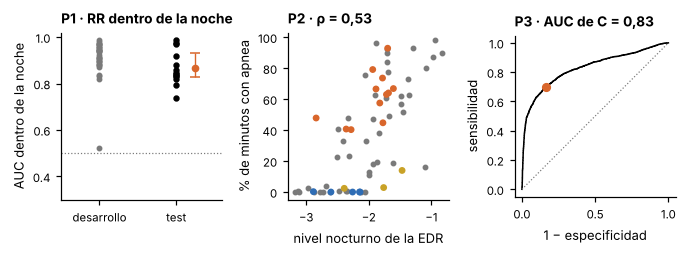

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.4))
ax[0].scatter(np.full(len(dentro_d), 0), dentro_d["AUC RR"], s=8, color=GRIS)
ax[0].scatter(np.full(len(dentro_t), 1), dentro_t["AUC RR"], s=10, color="black")
ax[0].errorbar(1.25, m1, yerr=[[m1 - l1], [h1 - m1]], fmt="o", color=APNEA, ms=4, capsize=3)
ax[0].axhline(0.5, color=GRIS, ls=":", lw=0.8)
ax[0].set(xticks=[0, 1], xticklabels=["desarrollo", "test"], xlim=(-0.5, 1.6), ylim=(0.3, 1.02),
          ylabel="AUC dentro de la noche", title="P1 · RR dentro de la noche")
ax[1].scatter(niv_d.EDR_noche, 100 * niv_d.frac, s=8, color=GRIS)
ax[1].scatter(niv_t.EDR_noche, 100 * niv_t.frac, s=12, c=[COLORES_CAT[c] for c in niv_t.category])
ax[1].set(xlabel="nivel nocturno de la EDR", ylabel="% de minutos con apnea", title=f"P2 · ρ = {m2:.2f}".replace(".", ","))
o_ = np.argsort(-c_t); yy = y_t[o_]
ax[2].plot(np.r_[0, np.cumsum(1 - yy) / (1 - yy).sum()], np.r_[0, np.cumsum(yy) / yy.sum()], color="black", lw=1)
ax[2].plot(1 - op["especificidad"], op["sensibilidad"], "o", color=APNEA, ms=5)
ax[2].plot([0, 1], [0, 1], ":", color=GRIS, lw=0.8)
ax[2].set(xlabel="1 − especificidad", ylabel="sensibilidad", title=f"P3 · AUC de C = {m3:.2f}".replace(".", ","), aspect="equal")
fig.tight_layout()
guardar(fig, "11_predicciones")

**Cómo leer la figura.** Izquierda: el AUC dentro de cada noche de test (negro) junto a los de desarrollo (gris), con la media de test y su intervalo (naranja). Centro: cada noche de test coloreada por categoría (A, B, C) sobre las de desarrollo, con el nivel de la EDR del detector final. Derecha: la curva ROC de C en test, con el punto del umbral fijado en desarrollo.

## 4. Preguntas secundarias

### 4.1 El detector final contra la versión evaluada en `05`

Primero, el control: la versión evaluada, recalculada ahora sobre test, tiene que repetir lo que guardó `05` en `docs/resultados_test.json`. Después, la diferencia final − evaluada en los minutos que evalúan las dos, con un bootstrap pareado de personas (2000 sorteos) y Holm sobre las 4 medidas. Es descriptiva: aunque la versión evaluada resultara mejor, no se vuelve a ella (`docs/plan_test_final.md`).

In [7]:
def predicciones(e):
    dn = pd.DataFrame([{"AUC": auc(g.P_RR, g.label)} for _, g in e.groupby("record") if con_ambos(g)])
    nv = e.groupby("record").agg(EDR_noche=("EDR_noche", "first"), frac=("label", "mean"))
    return [dn.AUC.mean(), spearmanr(nv.EDR_noche, nv.frac)[0], auc(e.C, e.label)]


repro = pd.DataFrame({"recalculado": predicciones(et_ev) + list(metricas(et_ev.label, et_ev.decision).values()),
                      "guardado en 05": [v["valor"] for v in RES_05["predicciones"].values()]
                      + [v["valor"] for v in RES_05["clasificacion_C"].values()]},
                     index=list(RES_05["predicciones"]) + list(RES_05["clasificacion_C"]))
repro["coincide"] = np.isclose(repro.recalculado, repro["guardado en 05"], rtol=0, atol=1e-9)
REPRODUCE_05 = bool(repro.coincide.all()) and len(et_ev) == RES_05["minutos_evaluados"]
print("la versión evaluada repite 05:", REPRODUCE_05, "(no aplica en modo ensayo)" if ENSAYO else "")
repro.round(4)

la versión evaluada repite 05: True 


,recalculado,guardado en 05,coincide
P1 · AUC dentro de la noche del RR (media),0.8688,0.8688,True
P2 · ρ entre el nivel EDR de la noche y el % de apnea,0.6581,0.6581,True
P3 · AUC de C con todos los minutos,0.8486,0.8486,True
sensibilidad,0.7088,0.7088,True
especificidad,0.8343,0.8343,True
exactitud,0.7801,0.7801,True


In [8]:
comun = et.merge(et_ev[["record", "minute", "C", "decision"]], on=["record", "minute"], suffixes=("", "_ev"))
s_c = comun.subject.to_numpy()
rng_c = np.random.default_rng(2026)
pers_c = np.unique(s_c)
IDX_C = [indices(s_c, rng_c.choice(pers_c, len(pers_c))) for _ in range(2000)]


def medidas_c(y, c, d):
    return {**metricas(y, d), "AUC de C": auc(c, y)}


def dif_versiones(i):
    y = comun.label.to_numpy()[i]
    a = medidas_c(y, comun.C.to_numpy()[i], comun.decision.to_numpy()[i])
    b = medidas_c(y, comun.C_ev.to_numpy()[i], comun.decision_ev.to_numpy()[i])
    return {k: a[k] - b[k] for k in a}, a, b


d0, fin0, ev0 = dif_versiones(np.arange(len(comun)))
boot_v = pd.DataFrame([dif_versiones(i)[0] for i in IDX_C])
p_v = {k: p_bootstrap(boot_v[k]) for k in d0}
ph_v = holm(p_v)
tab_v = pd.DataFrame({"final": fin0, "evaluada": ev0, "final − evaluada": d0,
                      "IC 95 %": {k: "{:+.3f} a {:+.3f}".format(*ic(boot_v[k])) for k in d0},
                      "p": p_v, "p de Holm": ph_v})
print(f"minutos comunes: {len(comun)} (final {len(et)}, evaluada {len(et_ev)})")
tab_v.round(4)

minutos comunes: 8844 (final 8844, evaluada 8844)


,final,evaluada,final − evaluada,IC 95 %,p,p de Holm
sensibilidad,0.6988,0.7088,-0.0099,-0.078 a +0.071,0.747,1.0
especificidad,0.8329,0.8343,-0.0014,-0.131 a +0.100,0.973,1.0
exactitud,0.7750,0.7801,-0.0051,-0.067 a +0.054,0.863,1.0
AUC de C,0.8274,0.8486,-0.0212,-0.098 a +0.023,0.541,1.0


### 4.2 C contra F y el RR solo

Las tres features con el pipeline final, cada una con su umbral de Youden de desarrollo, en las 7 medidas de `05` §3.1. Las diferencias C − F y C − RR solo salen de un bootstrap **pareado** de personas (2000 sorteos): en cada sorteo, las tres features se evalúan con los mismos minutos y noches, y una persona sorteada dos veces cuenta como dos noches. Holm sobre todas las diferencias que tienen un p, como en `06` §5.

In [9]:
def medidas(tab, feat):
    """Las 7 medidas de una feature, en los minutos de `tab`."""
    x, y = tab[COL[feat]].to_numpy(), tab.label.to_numpy()
    pred = (x > U[feat]).astype(int)
    aucs_n = [auc(g_[COL[feat]], g_.label) for _, g_ in tab.groupby("record") if con_ambos(g_)]
    nn = tab.assign(p=pred).groupby("record").agg(real=("label", "mean"), est=("p", "mean"), categ=("category", "first"))
    return {**metricas(y, pred), "AUC (todos los minutos)": auc(x, y),
            "AUC dentro de la noche (media)": np.mean(aucs_n) if aucs_n else np.nan,
            "ρ por noche": spearmanr(nn.real, nn.est)[0] if len(nn) > 2 else np.nan,
            "% marcado en controles": 100 * nn[nn.categ == "C"].est.mean() if (nn.categ == "C").any() else np.nan}


def medidas_sorteo(so):
    tab_b = pd.concat([et[et.subject == u].assign(record=lambda d_, k=k: d_.record + f"#{k}") for k, u in enumerate(so)],
                      ignore_index=True)
    return {f_: medidas(tab_b, f_) for f_ in COL}


punto = {f_: medidas(et, f_) for f_ in COL}
boot_f = [medidas_sorteo(so) for so in SORTEOS_MIN[:2000]]
tabla_feat = pd.DataFrame(punto).T
fam = {}
for otra in ("F", "RR solo"):
    for m_ in tabla_feat.columns:
        fam[(otra, m_)] = (punto["C"][m_] - punto[otra][m_], np.array([b_["C"][m_] - b_[otra][m_] for b_ in boot_f], float))
p_f = {k: p_bootstrap(b) for k, (_, b) in fam.items()}
ph_f = holm(p_f)
dif_feat = pd.DataFrame([{"C contra": k[0], "medida": k[1], "C − otra": d, "IC 95 %": "{:+.3f} a {:+.3f}".format(*ic(b)),
                          "p": p_f[k], "p de Holm": ph_f.get(k, np.nan)} for k, (d, b) in fam.items()]).set_index(["C contra", "medida"])
tabla_feat.round(3)

,sensibilidad,especificidad,exactitud,AUC (todos los minutos),AUC dentro de la noche (media),ρ por noche,% marcado en controles
C,0.699,0.833,0.775,0.827,0.869,0.734,6.111
F,0.758,0.726,0.740,0.814,0.834,0.754,19.521
RR solo,0.742,0.698,0.717,0.807,0.869,0.577,34.135


In [10]:
print(f"{dif_feat.p.notna().sum()} diferencias con p · significativas sin corregir: {(dif_feat.p < 0.05).sum()} · "
      f"con Holm: {(dif_feat['p de Holm'] < 0.05).sum()}")
dif_feat.round(4)

13 diferencias con p · significativas sin corregir: 3 · con Holm: 3


C − otra            IC 95 %      p  \
C contra medida                                                               
F        sensibilidad                     -0.0589    -0.241 a +0.031  0.257   
         especificidad                     0.1065    +0.048 a +0.154  0.000   
         exactitud                         0.0351    -0.024 a +0.106  0.281   
         AUC (todos los minutos)           0.0133    -0.076 a +0.068  0.675   
         AUC dentro de la noche (media)    0.0353    -0.000 a +0.082  0.054   
         ρ por noche                      -0.0201    -0.233 a +0.085  0.941   
         % marcado en controles          -13.4095   -21.260 a -8.316  0.000   
RR solo  sensibilidad                     -0.0429    -0.182 a +0.022  0.281   
         especificidad                     0.1346    -0.033 a +0.295  0.136   
         exactitud                         0.0579    -0.037 a +0.193  0.290   
         AUC (todos los minutos)           0.0206    -0.087 a +0.112  0.717   
         AUC dentro de la noche (media)    0.0000    +0.000 a +0.000    NaN   
         ρ por noche                       0.1573    -0.141 a +0.613  0.365   
         % marcado en controles          -28.0243  -46.457 a -14.924  0.000   

                                         p de Holm  
C contra medida                                     
F        sensibilidad                         1.00  
         especificidad                        0.00  
         exactitud                            1.00  
         AUC (todos los minutos)              1.00  
         AUC dentro de la noche (media)       0.54  
         ρ por noche                          1.00  
         % marcado en controles               0.00  
RR solo  sensibilidad                         1.00  
         especificidad                        1.00  
         exactitud                            1.00  
         AUC (todos los minutos)              1.00  
         AUC dentro de la noche (media)        NaN  
         ρ por noche                          1.00  
         % marcado en controles               0.00

Para el % marcado en controles, una diferencia negativa favorece a C. Dentro de la noche, C ordena los minutos igual que el RR (el término de la EDR es constante en la noche), así que esa diferencia es cero y no tiene p.

### 4.3 Por noche

El % de minutos marcados como apnea en cada noche contra el % real, los minutos marcados en los controles (categoría C, sin apnea) y cuántos minutos se evalúan en cada noche.

ρ por noche: 0.734 (IC 95 % 0.021 a 0.899) · % marcado en controles: 6.1


,real,estimada,exactitud,categoria,persona,evaluados,minutos
record,,,,,,,
a11,47.84,0.00,0.52,A,S10,464,464
b05,13.95,58.95,0.55,B,S17,380,428
x26,66.60,29.51,0.57,A,S28,515,516
a06,40.71,5.34,0.61,A,S06,506,506
x15,40.32,3.23,0.62,A,S06,496,496
x13,57.54,31.55,0.68,A,S28,504,504
x30,64.05,69.55,0.74,A,S07,509,509
x01,73.67,60.51,0.75,A,S07,509,509
a07,63.04,80.83,0.76,A,S07,506,506


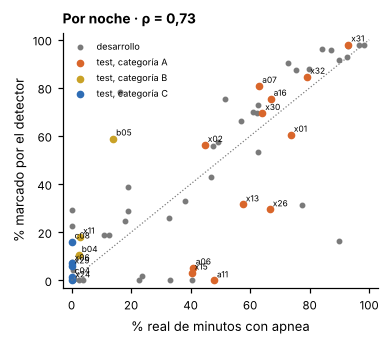

In [11]:
noches_t = (et.assign(ok=(et.decision == et.label)).groupby("record")
            .agg(real=("label", "mean"), estimada=("decision", "mean"), exactitud=("ok", "mean"),
                 categoria=("category", "first"), persona=("subject", "first"), evaluados=("label", "size")))
noches_t["minutos"] = T.groupby("record").size().reindex(noches_t.index)
noches_t[["real", "estimada"]] *= 100
noches_d = ed.groupby("record").agg(real=("label", "mean"), estimada=("decision", "mean"))
s_n = noches_t.persona.to_numpy()
b_n = np.array([spearmanr(noches_t.real.to_numpy()[i], noches_t.estimada.to_numpy()[i])[0]
                for i in (indices(s_n, so) for so in sorteos(s_n))])
rho_n = spearmanr(noches_t.real, noches_t.estimada)[0]

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.scatter(100 * noches_d.real, 100 * noches_d.estimada, s=8, color=GRIS, label="desarrollo")
for cat, g_ in noches_t.groupby("categoria"):
    ax.scatter(g_.real, g_.estimada, s=16, color=COLORES_CAT[cat], label=f"test, categoría {cat}")
for r_, f_ in noches_t.iterrows():
    ax.annotate(r_, (f_.real, f_.estimada), fontsize=5.5, xytext=(2, 2), textcoords="offset points")
ax.plot([0, 100], [0, 100], ":", color=GRIS, lw=0.8)
ax.set(xlabel="% real de minutos con apnea", ylabel="% marcado por el detector", xlim=(-3, 103), ylim=(-3, 103),
       title=f"Por noche · ρ = {rho_n:.2f}".replace(".", ","))
ax.legend(fontsize=6, loc="upper left")
fig.tight_layout()
guardar(fig, "11_por_noche")
print(f"ρ por noche: {rho_n:.3f} (IC 95 % {ic(b_n)[0]:.3f} a {ic(b_n)[1]:.3f}) · "
      f"% marcado en controles: {noches_t[noches_t.categoria == 'C'].estimada.mean():.1f}")
noches_t.sort_values("exactitud").round(2)

### 4.4 Desarrollo y test

Las medidas del detector final en test, al lado de las de su validación cruzada por personas en desarrollo (la del control 2), que es la estimación de lo que se esperaba en personas nuevas. En desarrollo, el AUC con todos los minutos es el promedio de los AUC de cada grupo de la validación cruzada, así que esa fila se compara solo de forma aproximada.

In [12]:
y_r = r_dev.label.to_numpy()
aucs_g = [auc(r_dev.margen[r_dev.grupo == k], y_r[r_dev.grupo == k]) for k in sorted(r_dev.grupo.unique())]
nn_d = r_dev.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
aucs_nd = [auc(g_.margen, g_.label) for _, g_ in r_dev.groupby("record") if con_ambos(g_)]
DEV_CV = {**metricas(y_r, r_dev.pred), "AUC (todos los minutos)": float(np.mean(aucs_g)),
          "AUC dentro de la noche (media)": float(np.mean(aucs_nd)), "ρ por noche": spearmanr(nn_d.real, nn_d.est)[0],
          "% marcado en controles": 100 * nn_d[nn_d.index.map(CATEG) == "C"].est.mean()}
comp = pd.DataFrame({"desarrollo (validación cruzada)": DEV_CV, "test": punto["C"],
                     "IC 95 % (test)": {m_: "{:.3f} a {:.3f}".format(*ic([b_["C"][m_] for b_ in boot_f])) for m_ in DEV_CV}})
comp.round(3)

,desarrollo (validación cruzada),test,IC 95 % (test)
sensibilidad,0.780,0.699,0.298 a 0.906
especificidad,0.863,0.833,0.725 a 0.930
exactitud,0.830,0.775,0.694 a 0.865
AUC (todos los minutos),0.888,0.827,0.627 a 0.939
AUC dentro de la noche (media),0.908,0.869,0.826 a 0.929
ρ por noche,0.739,0.734,0.006 a 0.902
% marcado en controles,9.539,6.111,3.515 a 16.142


## 5. Resultados guardados

Se guardan en `docs/resultados_test_final.json` para el informe.

In [13]:
RESULTADOS = {
    "detector": "final (src/detector_final.py)", "sha256_parametros": SHA256_PARAMS,
    "registros": len(TEST), "personas": int(SUJETO[TEST].nunique()), "minutos_evaluados": int(len(et)),
    "predicciones": {k: {"valor": float(v["valor"]), "ic95": v["IC 95 %"], "se_cumple": bool(v["se cumple"])}
                     for k, v in veredicto.iterrows()},
    "H_se_sostiene": H_SOSTENIDA,
    "clasificacion_C": {k: {"valor": float(v), "ic95": "{:.3f} a {:.3f}".format(*ic(b3[k]))} for k, v in op.items()},
    "version_evaluada_repite_05": REPRODUCE_05,
    "final_contra_evaluada": tab_v.reset_index().rename(columns={"index": "medida"}).to_dict(orient="records"),
    "comparacion": {f_: {k: float(v) for k, v in punto[f_].items()} for f_ in COL},
    "diferencias": dif_feat.reset_index().to_dict(orient="records"),
    "rho_por_noche": {"valor": float(rho_n), "ic95": "{:.3f} a {:.3f}".format(*ic(b_n))},
    "desarrollo_validacion_cruzada": {k: float(v) for k, v in DEV_CV.items()},
    "umbrales_desarrollo": {k: float(v) for k, v in U.items()},
}
if not ENSAYO:
    (ROOT / "docs" / "resultados_test_final.json").write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=str))
print(json.dumps(RESULTADOS["predicciones"], indent=1, ensure_ascii=False))

{
 "P1 · AUC dentro de la noche del RR (media)": {
  "valor": 0.868820503547969,
  "ic95": "0.827 a 0.930",
  "se_cumple": true
 },
 "P2 · ρ entre el nivel EDR de la noche y el % de apnea": {
  "valor": 0.5305698153912726,
  "ic95": "-0.152 a 0.732",
  "se_cumple": false
 },
 "P3 · AUC de C con todos los minutos": {
  "valor": 0.8273743618085656,
  "ic95": "0.627 a 0.937",
  "se_cumple": true
 }
}


## 6. Conclusión

*Escrita después de la única ejecución (2026-11-24), solo con los resultados de arriba. No se recalculó nada ni se cambió el código.*

**Con el detector final, H no se sostiene en test: se cumplen P1 y P3, pero no P2.**

| Predicción | Test | IC 95 % | ¿Se cumple? |
|---|---|---|---|
| P1 · AUC dentro de la noche del RR | 0,869 | 0,827 a 0,930 | sí |
| P2 · ρ entre el nivel nocturno de la EDR y el % de apnea | 0,531 | −0,152 a 0,732 | **no**: el intervalo incluye el 0 |
| P3 · AUC de C con todos los minutos | 0,827 | 0,627 a 0,937 | sí |

- **El control del cálculo se cumple.** P1 repite exactamente el valor y el intervalo de `05`, como se esperaba, porque el RR es el mismo. La versión evaluada, recalculada sobre test, también repite `05`.
- **Qué dice esto de cada parte de la hipótesis** (`objetivos_hipotesis.md`):
  - **(a) dentro de la noche** se sostiene: la potencia del RR es mayor en los minutos con apnea que en los normales de la misma noche;
  - **(b) entre noches** no se demuestra con el detector final. En estas 20 noches de 10 personas, el nivel nocturno de la EDR sin Wiener acompaña al % de apnea con ρ = 0,531, pero el intervalo incluye el 0. Con 10 personas el intervalo es ancho, así que esto tampoco demuestra que la relación no exista (limitación 9);
  - **(c) detección:** C clasifica los minutos de personas nuevas mejor que el azar, con el umbral fijado en desarrollo (sensibilidad 0,699, especificidad 0,833, exactitud 0,775).
- **El plan preveía que, si fallaba P2, C se reduciría en la práctica al RR solo. En test eso no pasa del todo:** C marca el 6,1 % de los minutos en los controles, contra 34,1 % del RR solo (−28,0 puntos, resiste Holm). El término de la EDR sigue bajando las falsas alarmas en las noches sin apnea, aunque no ordene las noches por cantidad de apnea de forma demostrable.
- **Contra la versión evaluada en `05`, que solo difiere en el Wiener:**
  - en los mismos 8844 minutos no hay diferencia demostrable en sensibilidad, especificidad, exactitud ni AUC. La mayor es el AUC: −0,021 (IC −0,098 a +0,023, p de Holm = 1);
  - P2 baja de 0,658 (IC 0,117 a 0,786) a 0,531 (IC −0,152 a 0,732). En desarrollo también era algo menor (0,787 contra 0,83). Esa diferencia no estaba en el plan y no se puso a prueba;
  - según el plan, no se vuelve a la versión con Wiener: elegirla ahora sería elegir con test, y cualquier cambio necesitaría datos nuevos.
- **C contra F y el RR solo:** el mismo patrón que en `05`. Con Holm resisten 3 de 13 diferencias, las tres a favor de C en falsas alarmas: la especificidad contra F (+0,107) y el % marcado en los controles contra F (−13,4 puntos) y contra el RR solo (−28,0). En exactitud y AUC no hay diferencia demostrable.
- **Por noche:** ρ = 0,734 (IC 0,021 a 0,899) entre el % marcado y el real. Fallan las mismas noches que en `05`:
  - noches con apnea subestimadas: a11 (47,8 % real, 0 % marcado), a06 y x15 (de la misma persona), x26 y x13 (de otra);
  - una noche B sobreestimada: b05 (14 % real, 59 % marcado).
- **Desarrollo y test:** casi todas las medidas son algo menores en test que en la validación cruzada de desarrollo (exactitud 0,775 contra 0,830; AUC 0,827 contra 0,888). El % marcado en los controles es menor (6,1 contra 9,5) y el ρ por noche es igual (0,734 contra 0,739). Todos los valores de desarrollo caen dentro de los intervalos de test.

**En resumen:** el detector final ubica la apnea dentro de la noche y clasifica los minutos mejor que el azar en personas nuevas, y da pocas falsas alarmas en los controles. Pero con él no se demuestra en test que el nivel nocturno de la EDR acompañe a la cantidad de apnea de cada noche, así que la hipótesis completa no se sostiene con esta versión.